In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np
%matplotlib inline

In [4]:
df = pd.read_csv("FuelConsumption.csv")

# take a look at the dataset
df.head()



,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [5]:
import numpy as np
import matplotlib.pyplot as plt

def plot_scatter_simple(x, y, xlabel="X", ylabel="Y", title=None,
                        color="#2E86AB", alpha=0.6, figsize=(10, 6)):
    fig, ax = plt.subplots(figsize=figsize, dpi=110)
    x_arr, y_arr = np.asarray(x), np.asarray(y)

    ax.scatter(x_arr, y_arr, color=color, alpha=alpha, s=70,
               edgecolor='white', linewidth=1.2, zorder=3)

    # خط رگرسیون با numpy (بدون scipy)
    slope, intercept = np.polyfit(x_arr, y_arr, 1)
    line_x = np.linspace(x_arr.min(), x_arr.max(), 100)
    ax.plot(line_x, slope * line_x + intercept,
            color='#E63946', linewidth=2.5, zorder=4,
            label=f'y = {slope:.2f}x + {intercept:.2f}')

    # R² با numpy
    y_pred = slope * x_arr + intercept
    ss_res = np.sum((y_arr - y_pred) ** 2)
    ss_tot = np.sum((y_arr - y_arr.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    ax.text(0.03, 0.97, f'$R^2$ = {r2:.3f}', transform=ax.transAxes,
            fontsize=11, va='top',
            bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                      edgecolor='#ccc', alpha=0.9))

    ax.set_xlabel(xlabel, fontsize=13, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=13, fontweight='bold')
    ax.set_title(title or f'{ylabel} vs {xlabel}',
                 fontsize=15, fontweight='bold', pad=15)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='lower right', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()
    return ax


import numpy as np
import matplotlib.pyplot as plt

def plot_scatter_poly(x, y, xlabel="X", ylabel="Y", title=None,
                      color="#2E86AB", alpha=0.6, figsize=(10, 6),
                      degree=2):
    """
    نمودار پراکندگی با منحنی رگرسیون چندجمله‌ای (غیرخطی)
    
    degree : int — درجه منحنی (۲ = سهمی، ۳ = مکعبی، ...)
    """
    fig, ax = plt.subplots(figsize=figsize, dpi=110)
    x_arr, y_arr = np.asarray(x), np.asarray(y)

    # نقاط
    ax.scatter(x_arr, y_arr, color=color, alpha=alpha, s=70,
               edgecolor='white', linewidth=1.2, zorder=3,
               label='Data points')

    # برازش چندجمله‌ای (غیرخطی)
    coeffs = np.polyfit(x_arr, y_arr, degree)
    poly = np.poly1d(coeffs)

    # منحنی
    line_x = np.linspace(x_arr.min(), x_arr.max(), 300)
    line_y = poly(line_x)
    ax.plot(line_x, line_y, color='#E63946', linewidth=2.5, zorder=4,
            label=f'Polynomial fit (degree={degree})')

    # R² برای برازش چندجمله‌ای
    y_pred = poly(x_arr)
    ss_res = np.sum((y_arr - y_pred) ** 2)
    ss_tot = np.sum((y_arr - y_arr.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot

    # ساخت متن معادله
    terms = []
    for i, c in enumerate(coeffs):
        power = degree - i
        if power == 0:
            terms.append(f"{c:+.2f}")
        elif power == 1:
            terms.append(f"{c:+.2f}x")
        else:
            terms.append(f"{c:+.2f}x$^{power}$")
    eq_str = " ".join(terms)

    # باکس آماره
    stats_text = f'$R^2$ = {r2:.3f}\n{eq_str}'
    ax.text(0.03, 0.97, stats_text, transform=ax.transAxes,
            fontsize=10, va='top',
            bbox=dict(boxstyle='round,pad=0.6', facecolor='white',
                      edgecolor='#ccc', alpha=0.9))

    # برچسب‌ها
    ax.set_xlabel(xlabel, fontsize=13, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=13, fontweight='bold')
    ax.set_title(title or f'{ylabel} vs {xlabel} (non-linear fit)',
                 fontsize=15, fontweight='bold', pad=15)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='lower right', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()
    return ax

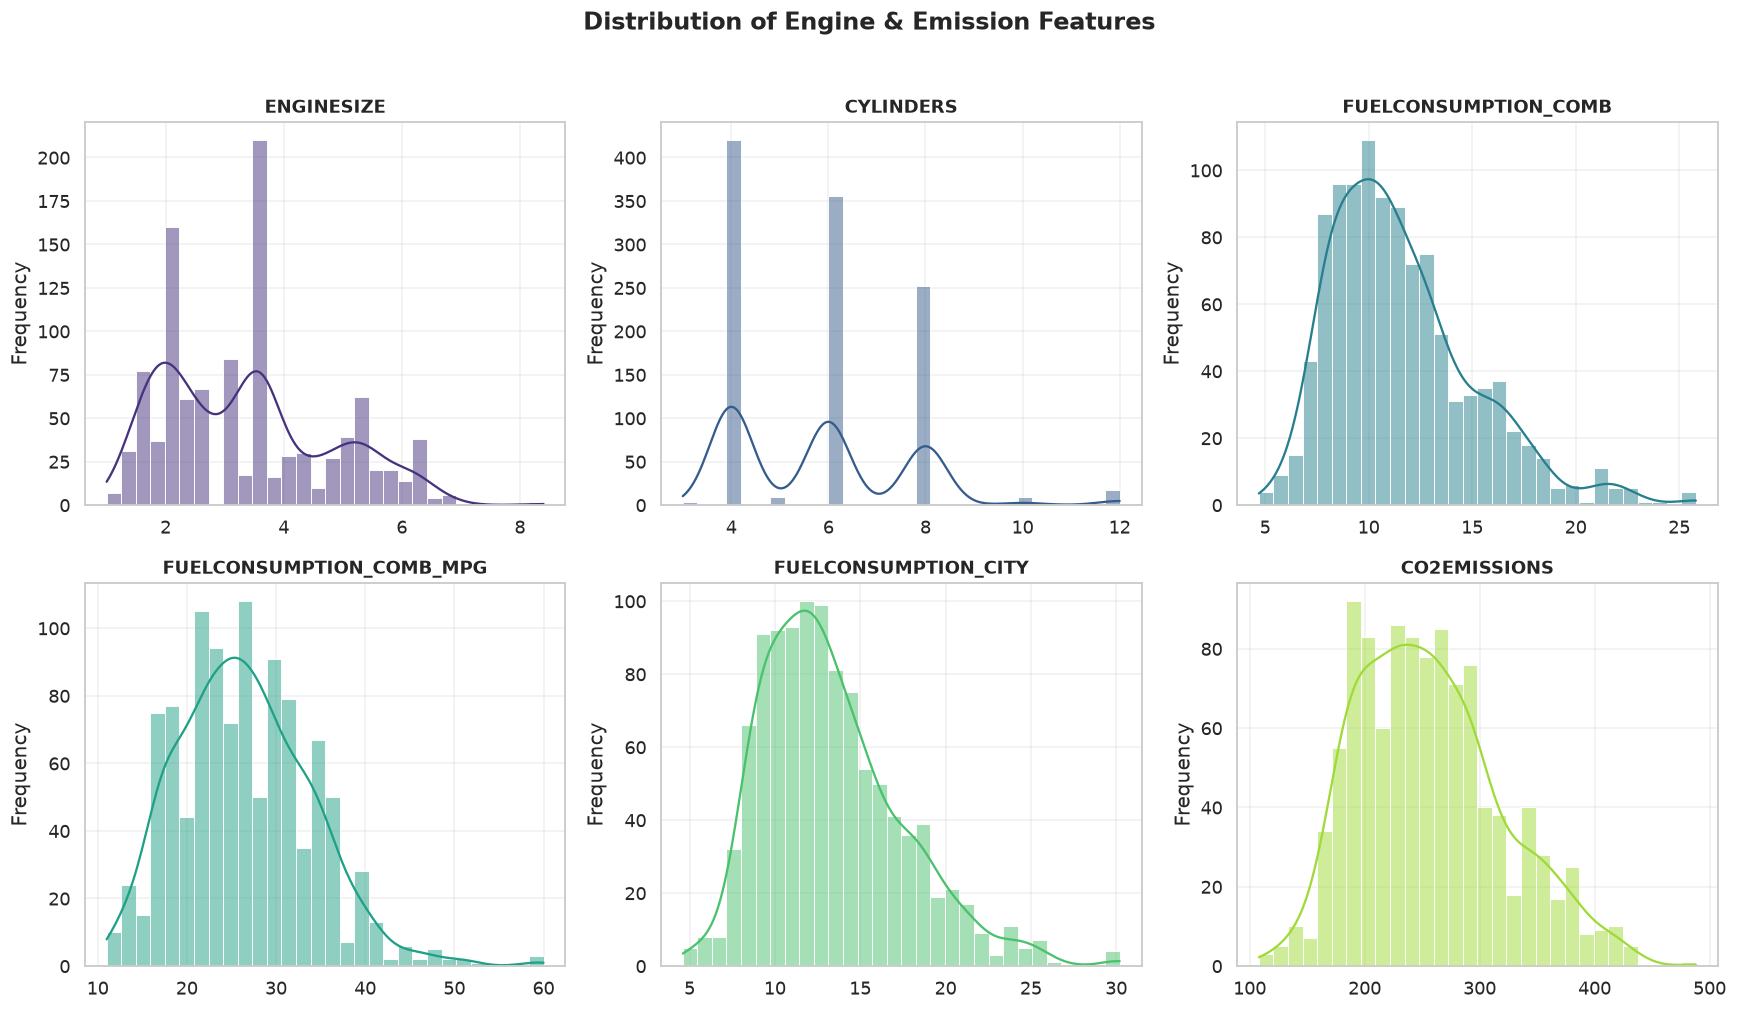

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1) انتخاب ستون‌ها (بدون تکرار) ---
cols = ['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB',
        'FUELCONSUMPTION_COMB_MPG', 'FUELCONSUMPTION_CITY', 'CO2EMISSIONS']

viz = df[cols].copy()
cdf =  df[cols].copy()
# --- 2) تنظیم استایل کلی ---
sns.set_style("whitegrid")
sns.set_context("notebook", font_scale=1.1)
plt.rcParams['figure.dpi'] = 110

# --- 3) ساخت شبکه‌ی 2×3 هیستوگرام با KDE ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

colors = sns.color_palette("viridis", len(cols))

for i, col in enumerate(cols):
    sns.histplot(
        data=viz,
        x=col,
        bins=30,
        kde=True,
        color=colors[i],
        edgecolor='white',
        linewidth=0.6,
        ax=axes[i]
    )
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')      # محور x رو خالی می‌کنیم چون عنوان بالا هست
    axes[i].set_ylabel('Frequency')
    axes[i].grid(alpha=0.3)

# --- 4) تنظیم فاصله‌ها و یک عنوان کلی ---
fig.suptitle('Distribution of Engine & Emission Features',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

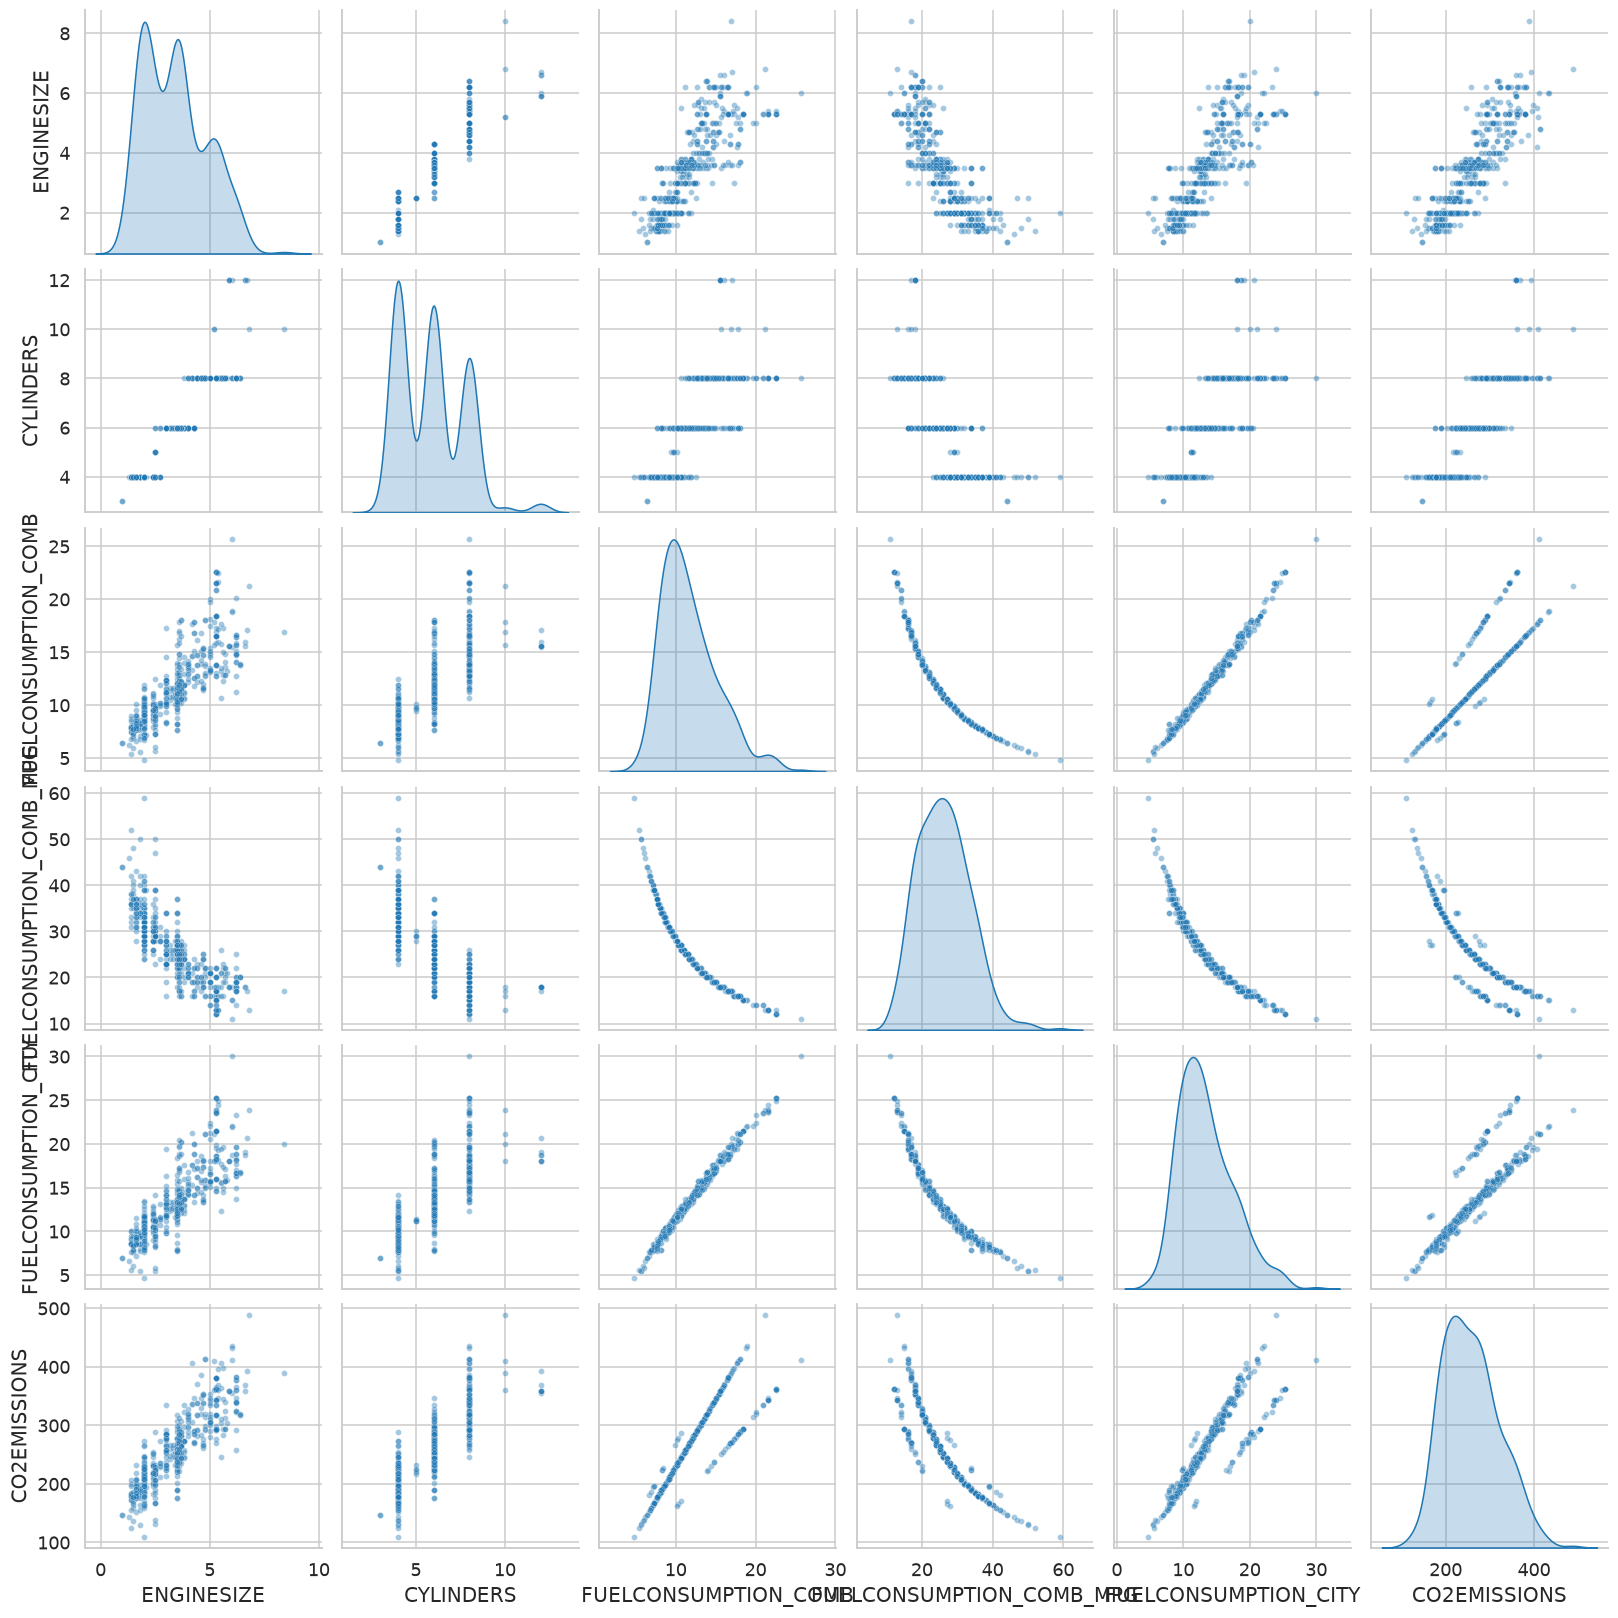

In [7]:
sns.pairplot(viz.sample(min(500, len(viz))), 
             diag_kind='kde', 
             plot_kws={'alpha':0.4, 's':15})
plt.show()

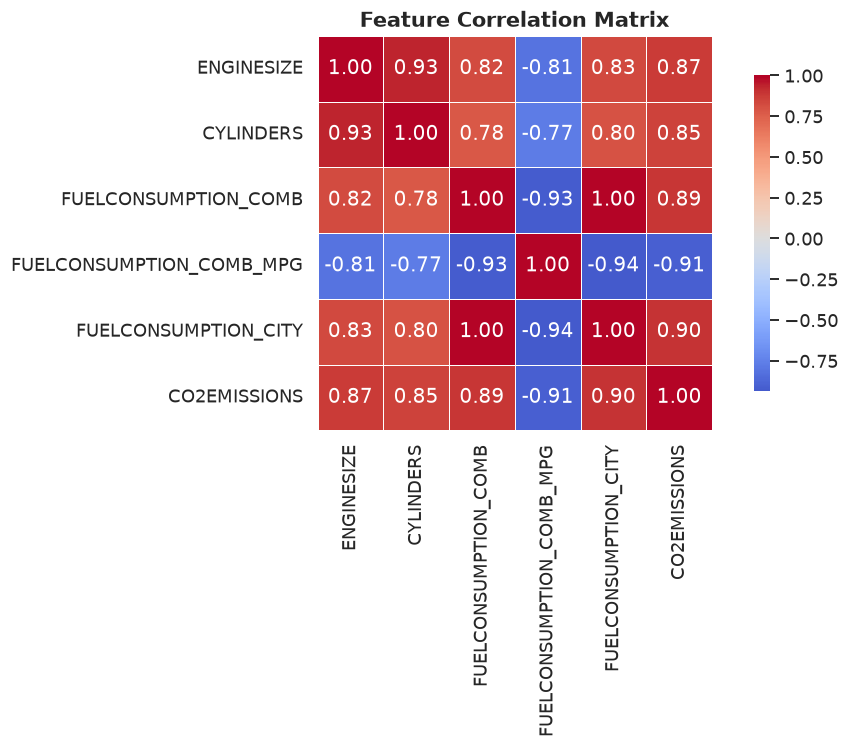

In [8]:
plt.figure(figsize=(10, 7))
sns.heatmap(viz.corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True,
            linewidths=0.5, cbar_kws={"shrink": .8})
plt.title("Feature Correlation Matrix", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error


# ---------- helper: plot fitted line/curve ---------- 
def _plot_fit(model, df, feature_col, target_col, title): # create plot 
    x_all = df[feature_col].values
    y_all = df[target_col].values
    
    x_smooth = np.linspace(x_all.min(), x_all.max(), 100).reshape(-1, 1)
    x_smooth_df = pd.DataFrame(x_smooth, columns=[feature_col])

    plt.scatter(x_all, y_all)
    plt.plot(x_smooth, model.predict(x_smooth_df), color="red")
    plt.xlabel(feature_col)
    plt.ylabel(target_col)
    plt.title(title)
    plt.show()


# ---------- 1) Linear Regression on a dataframe ----------
def linear_regression_analysis(df, feature_col, target_col, plot=True):
    X = df[[feature_col]]
    y = df[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    print(f"[Linear]      R² = {r2:.4f} | MSE = {mse:.4f}")

    if plot:
        _plot_fit(model, df, feature_col, target_col,
                  f"Linear Regression  (R²={r2:.4f})")

    # return model, y_test, y_pred, r2, mse


# ---------- 2) Polynomial Regression (degree=2) on a dataframe ----------
def polynomial_regression_analysis(df, feature_col, target_col, degree=2, plot=True):
    X = df[[feature_col]]
    y = df[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("lin",  LinearRegression()),
    ])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    if plot:
        _plot_fit(model, df, feature_col, target_col,
                  f"Polynomial Regression (deg={degree})  (R²={r2:.4f})")
    else :
        print(f"[Polynomial d={degree}]  R² = {r2:.4f} | MSE = {mse:.4f}")

    # return model, y_test, y_pred, r2, mse

[Linear]      R² = 0.7317 | MSE = 1109.3480


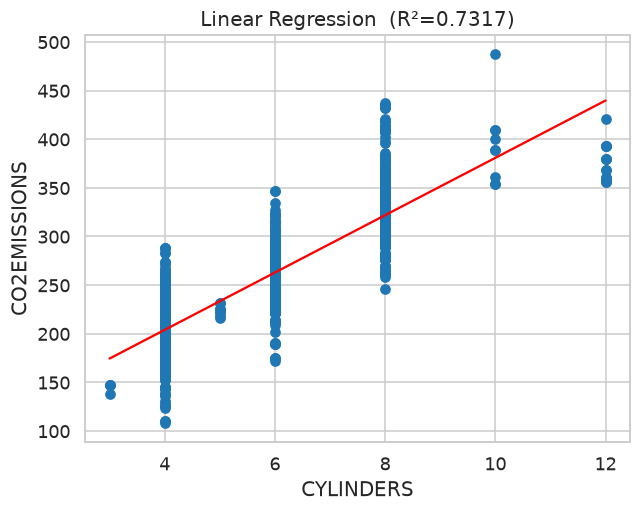

In [10]:
# Run on each dataframe — no manual splitting needed
linear_regression_analysis(cdf, "CYLINDERS", "CO2EMISSIONS")


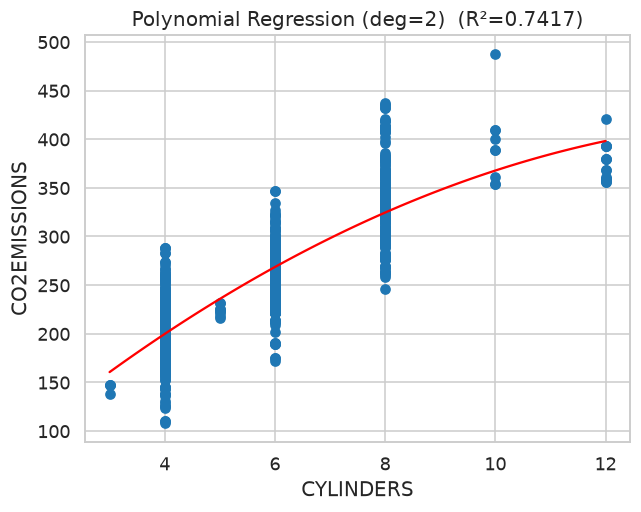

In [11]:
polynomial_regression_analysis(cdf, "CYLINDERS", "CO2EMISSIONS")


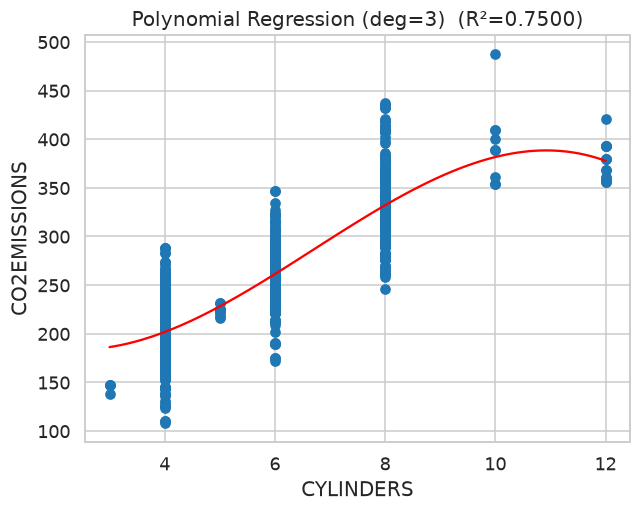

In [12]:
polynomial_regression_analysis(cdf, "CYLINDERS", "CO2EMISSIONS" , degree=3)


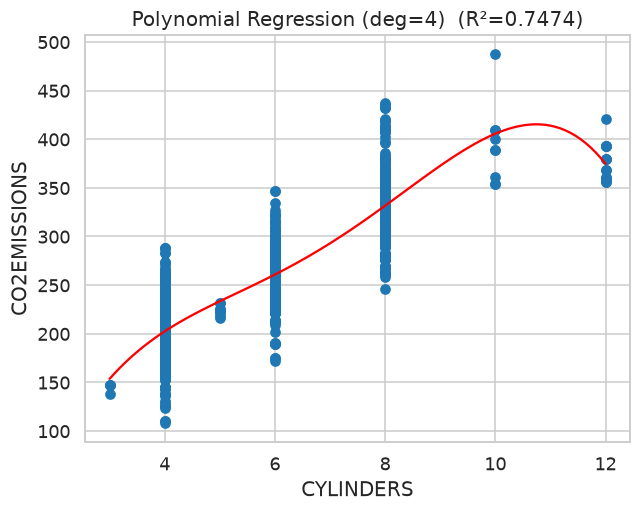

In [13]:
polynomial_regression_analysis(cdf, "CYLINDERS", "CO2EMISSIONS" , degree=4)


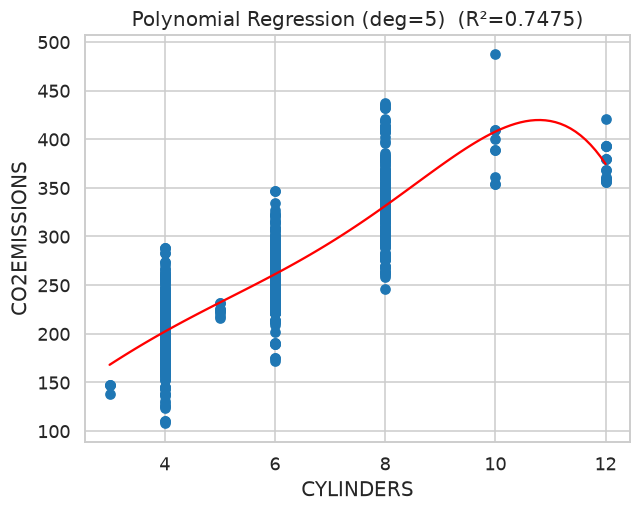

In [14]:
polynomial_regression_analysis(cdf, "CYLINDERS", "CO2EMISSIONS" , degree=5)


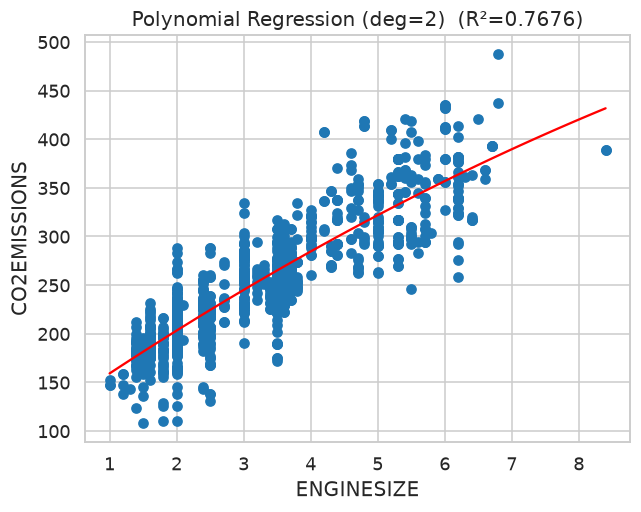

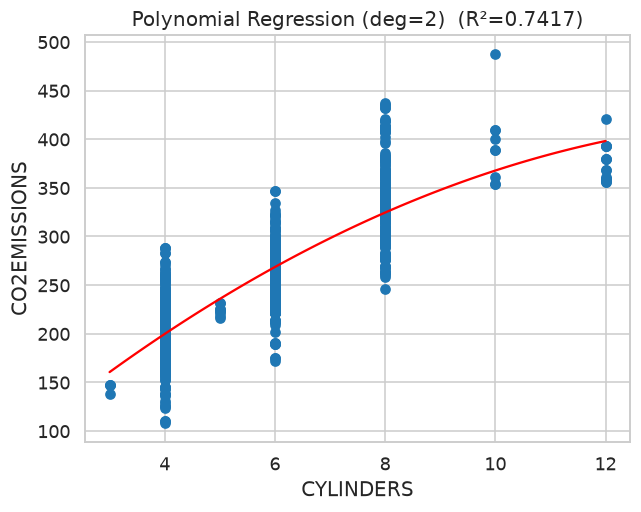

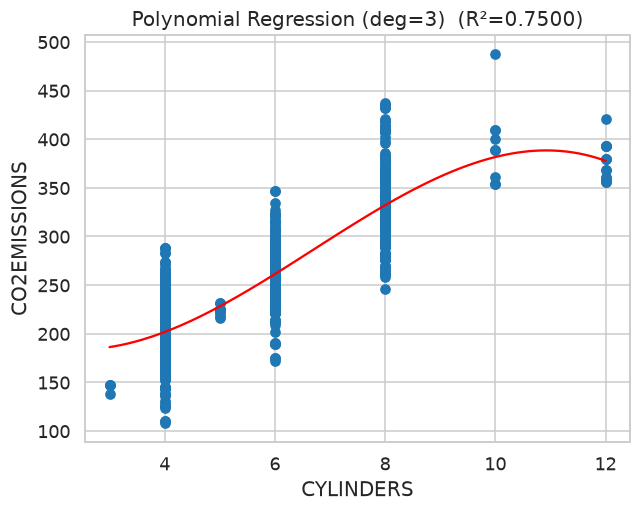

In [15]:
polynomial_regression_analysis(cdf, "ENGINESIZE", "CO2EMISSIONS" ) # engine size 1 
polynomial_regression_analysis(cdf, "CYLINDERS", "CO2EMISSIONS" , degree=2)

polynomial_regression_analysis(cdf, "CYLINDERS", "CO2EMISSIONS" , degree=3)



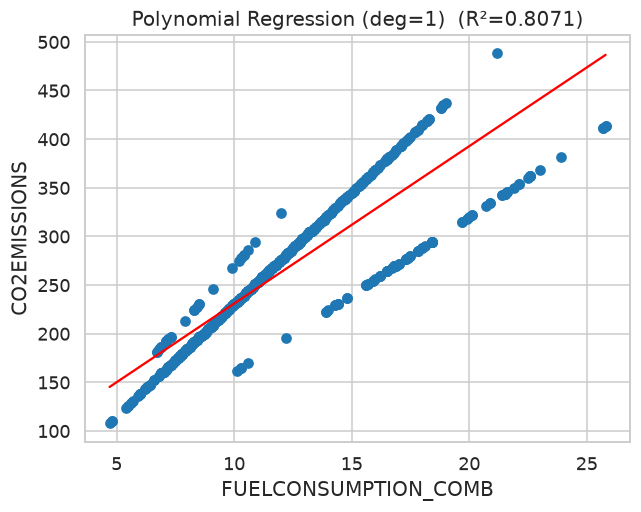

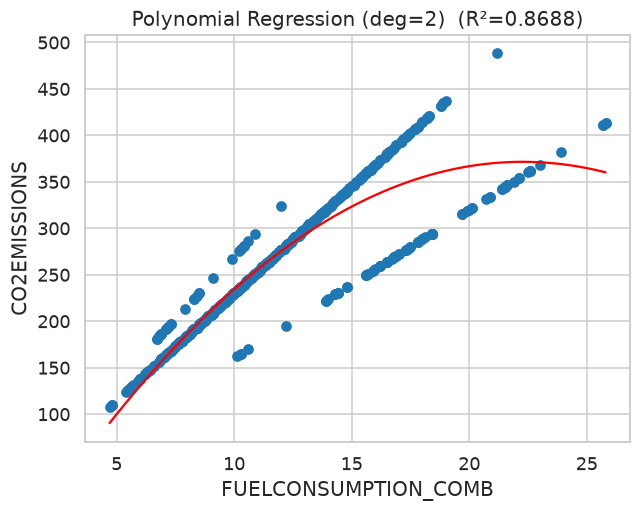

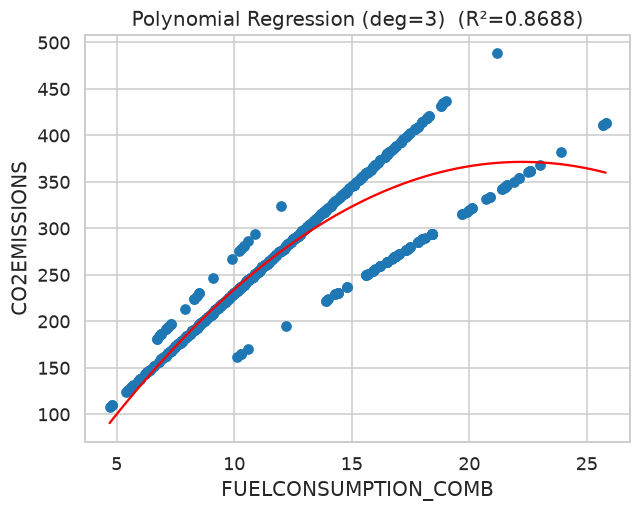

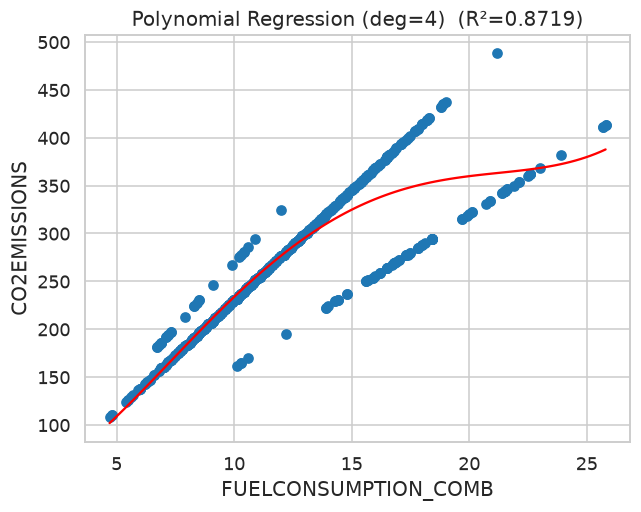

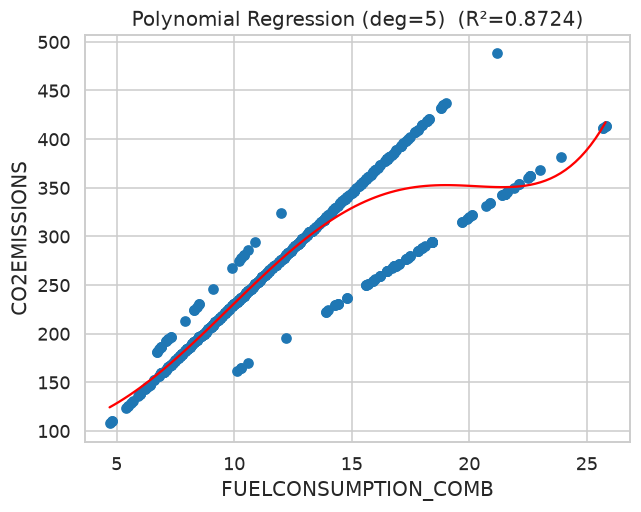

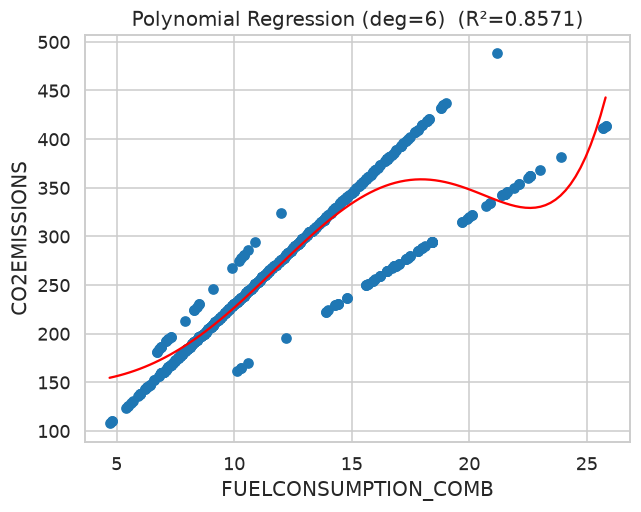

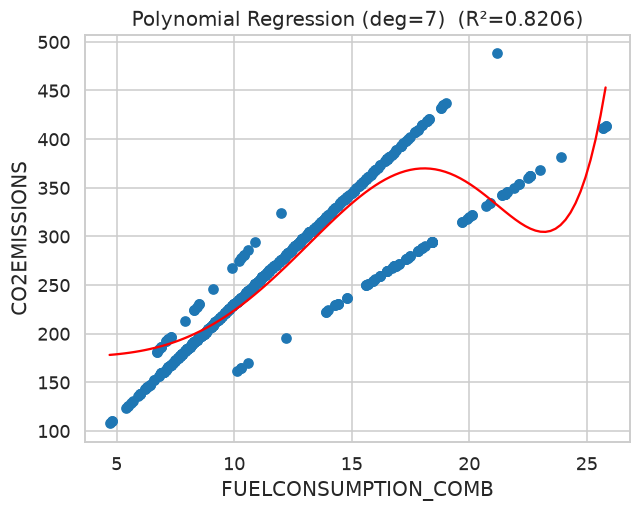

In [16]:
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB", "CO2EMISSIONS" ,degree=1) # engine size 1 
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB", "CO2EMISSIONS" , degree=2)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB", "CO2EMISSIONS" , degree=3)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB", "CO2EMISSIONS" , degree=4)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB", "CO2EMISSIONS" , degree=5)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB", "CO2EMISSIONS" , degree=6)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB", "CO2EMISSIONS" , degree=7)


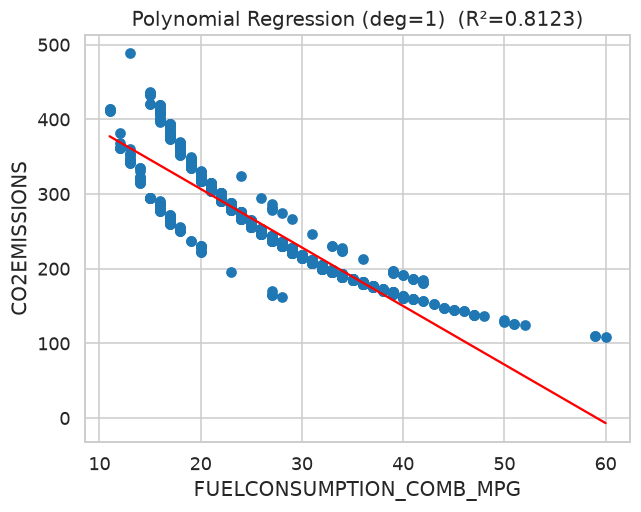

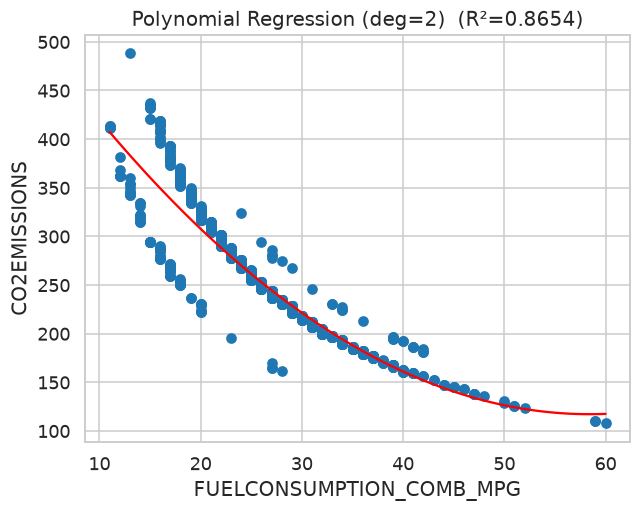

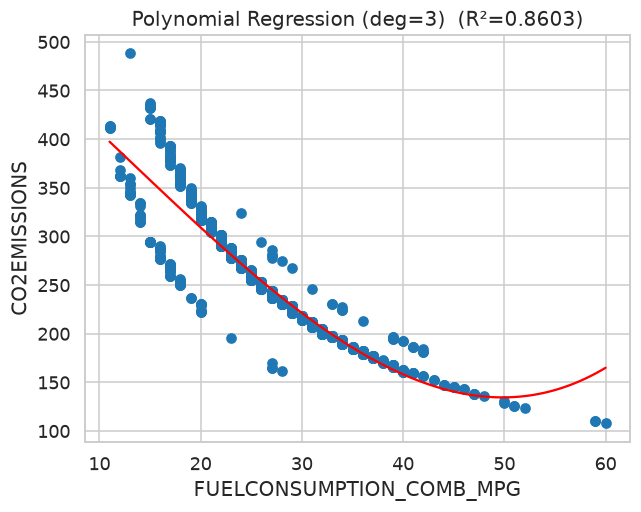

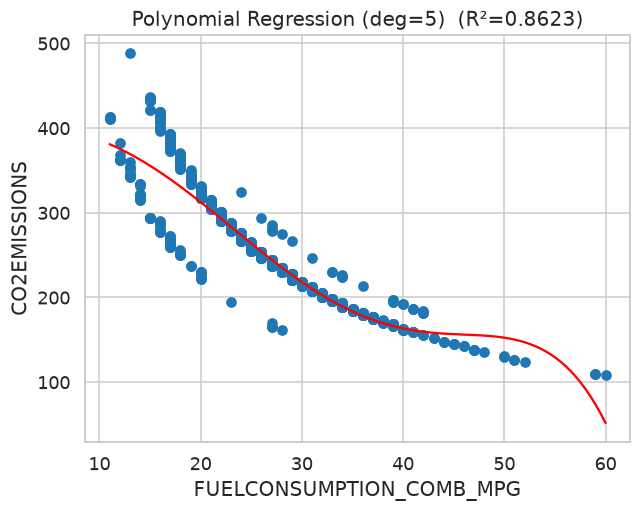

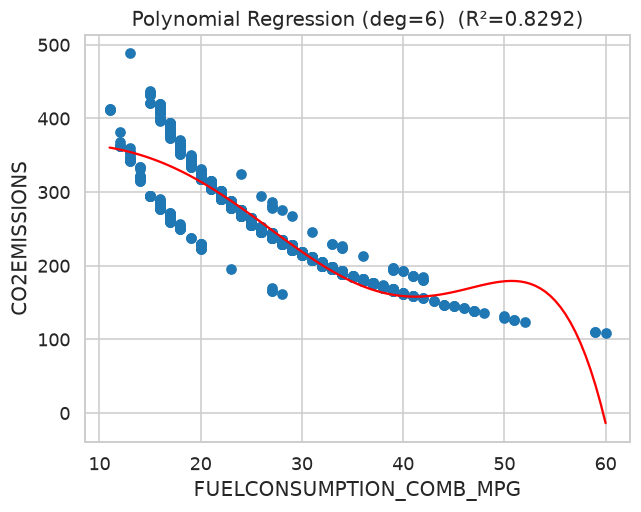

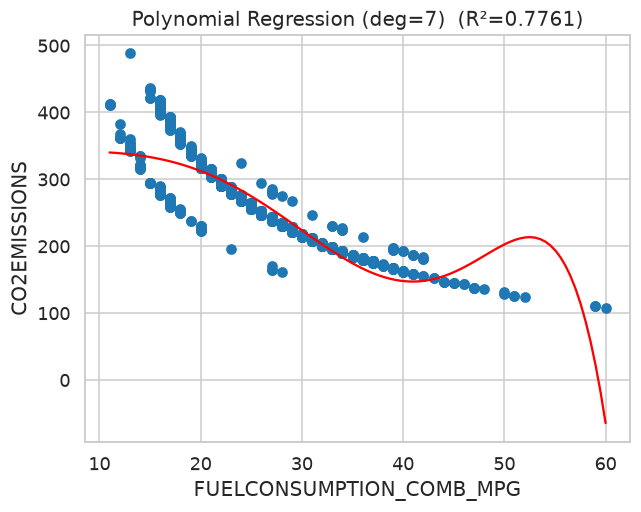

In [17]:
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB_MPG", "CO2EMISSIONS" ,degree=1) # engine size 1 
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB_MPG", "CO2EMISSIONS" , degree=2)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB_MPG", "CO2EMISSIONS" , degree=3)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB_MPG", "CO2EMISSIONS" , degree=5)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB_MPG", "CO2EMISSIONS" , degree=6)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_COMB_MPG", "CO2EMISSIONS" , degree=7)


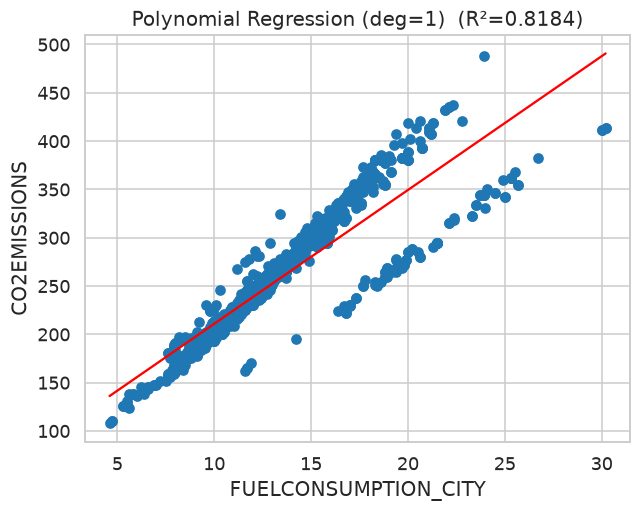

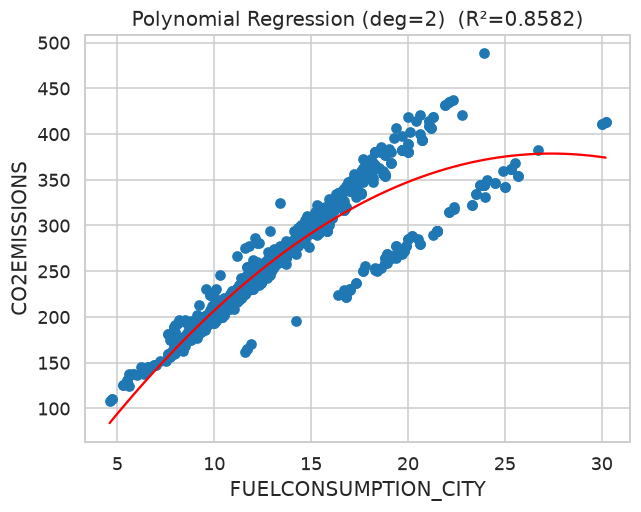

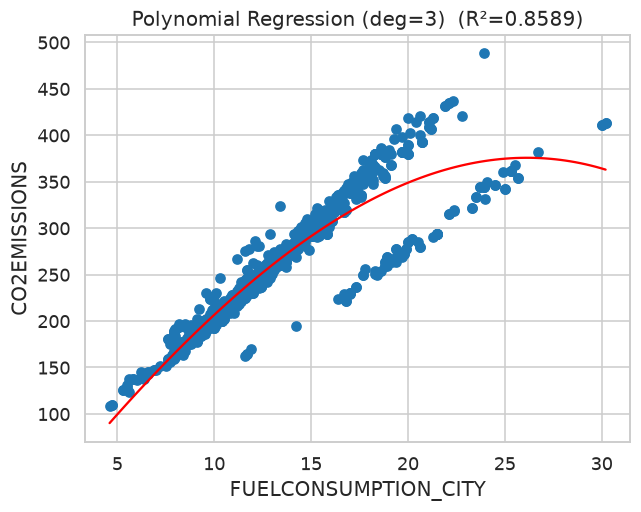

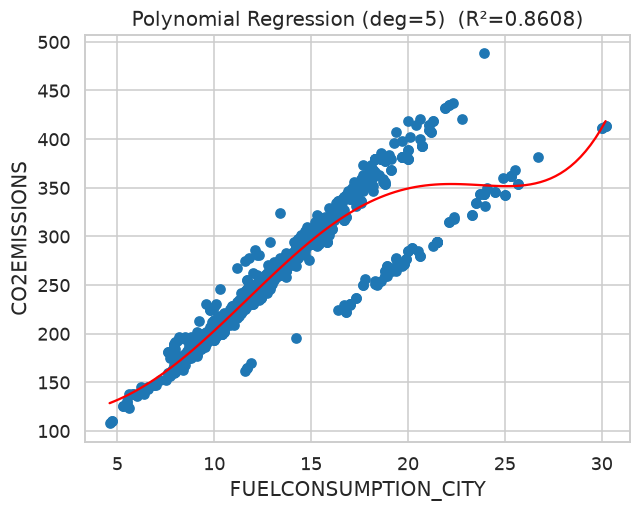

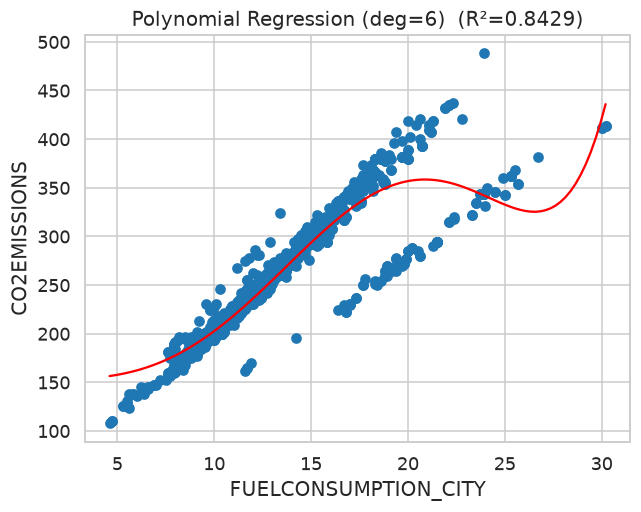

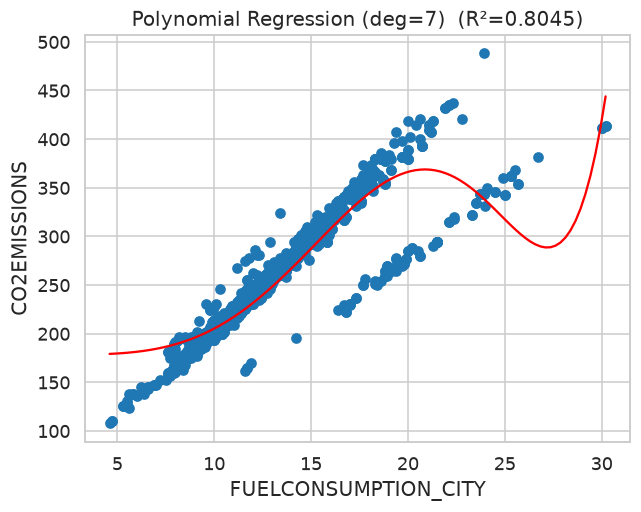

In [18]:
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_CITY", "CO2EMISSIONS" ,degree=1) # engine size 1 
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_CITY", "CO2EMISSIONS" , degree=2)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_CITY", "CO2EMISSIONS" , degree=3)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_CITY", "CO2EMISSIONS" , degree=5)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_CITY", "CO2EMISSIONS" , degree=6)
polynomial_regression_analysis(cdf, "FUELCONSUMPTION_CITY", "CO2EMISSIONS" , degree=7)


In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


# create noice 

# Input features
X = cdf[
    [
        'ENGINESIZE',
        'CYLINDERS',
        'FUELCONSUMPTION_COMB',
        'FUELCONSUMPTION_COMB_MPG',
        'FUELCONSUMPTION_CITY'
    ]
]

# Target
y = cdf['CO2EMISSIONS']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Apply a different polynomial degree to each feature
preprocessor = ColumnTransformer(
    transformers=[
        ('engine', 'passthrough', ['ENGINESIZE']),

        ('cylinders',
         PolynomialFeatures(degree=3, include_bias=False),
         ['CYLINDERS']),

        ('combined',
         PolynomialFeatures(degree=5, include_bias=False),
         ['FUELCONSUMPTION_COMB']),

        ('mpg',
         PolynomialFeatures(degree=4, include_bias=False),
         ['FUELCONSUMPTION_COMB_MPG']),

        ('city',
         PolynomialFeatures(degree=5, include_bias=False),
         ['FUELCONSUMPTION_CITY'])
    ],
    remainder='drop'
)

# Create the model
model = make_pipeline(
    preprocessor,
    LinearRegression()
)

# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Evaluate
print("Train R²:", model.score(X_train, y_train))
print("Test R²:", r2_score(y_test, y_pred))


Train R²: 0.8929862929437933
Test R²: 0.9077896235530611


In [24]:
# with noice 
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Input features
X = cdf[
    [
        'ENGINESIZE',
        'CYLINDERS',
        'FUELCONSUMPTION_COMB',
        'FUELCONSUMPTION_COMB_MPG',
        'FUELCONSUMPTION_CITY'
    ]
]

# Target
y = cdf['CO2EMISSIONS']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create noise ONLY for training targets
rng = np.random.default_rng(42)

noise = rng.normal(
    loc=0,
    scale=10,
    size=len(y_train)
)

y_train_noisy = y_train + noise

# Polynomial preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('engine', 'passthrough', ['ENGINESIZE']),

        ('cylinders',
         PolynomialFeatures(degree=3, include_bias=False),
         ['CYLINDERS']),

        ('combined',
         PolynomialFeatures(degree=5, include_bias=False),
         ['FUELCONSUMPTION_COMB']),

        ('mpg',
         PolynomialFeatures(degree=4, include_bias=False),
         ['FUELCONSUMPTION_COMB_MPG']),

        ('city',
         PolynomialFeatures(degree=5, include_bias=False),
         ['FUELCONSUMPTION_CITY'])
    ],
    remainder='drop'
)

# Create model
model = make_pipeline(
    preprocessor,
    LinearRegression()
)

# Train on noisy targets
model.fit(X_train, y_train_noisy)

# Predict on clean test features
y_pred = model.predict(X_test)

# Evaluate against clean targets
print("Train R² (noisy targets):",
      model.score(X_train, y_train_noisy))

print("Test R² (clean targets):",
      r2_score(y_test, y_pred))

Train R² (noisy targets): 0.8698990736229211
Test R² (clean targets): 0.9075249069980114


In [25]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error




features = [
    'ENGINESIZE',
    'CYLINDERS',
    'FUELCONSUMPTION_COMB',
    'FUELCONSUMPTION_COMB_MPG',
    'FUELCONSUMPTION_CITY'
]

X = cdf[features].copy()
y = cdf['CO2EMISSIONS'].copy()



X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)



rng = np.random.default_rng(42)

noise_scales = { # create noice for each property 
    'ENGINESIZE': 0.05,
    'CYLINDERS': 0.1,
    'FUELCONSUMPTION_COMB': 0.2,
    'FUELCONSUMPTION_COMB_MPG': 0.3,
    'FUELCONSUMPTION_CITY': 0.2
}

# Keep the original data unchanged
X_train_noisy = X_train.copy()

# Add noise only to training features
for feature, scale in noise_scales.items():

    noise = rng.normal(
        loc=0,
        scale=scale,
        size=len(X_train_noisy)
    )

    X_train_noisy[feature] = (
        X_train_noisy[feature] + noise
    )




def create_preprocessor():

    return ColumnTransformer(
        transformers=[
            (
                'engine',
                'passthrough',
                ['ENGINESIZE']
            ),

            (
                'cylinders',
                PolynomialFeatures(
                    degree=3,
                    include_bias=False
                ),
                ['CYLINDERS']
            ),

            (
                'combined',
                PolynomialFeatures(
                    degree=5,
                    include_bias=False
                ),
                ['FUELCONSUMPTION_COMB']
            ),

            (
                'mpg',
                PolynomialFeatures(
                    degree=4,
                    include_bias=False
                ),
                ['FUELCONSUMPTION_COMB_MPG']
            ),

            (
                'city',
                PolynomialFeatures(
                    degree=5,
                    include_bias=False
                ),
                ['FUELCONSUMPTION_CITY']
            )
        ],
        remainder='drop'
    )


# ==========================================
# 5. Train model on original data
# ==========================================

model_original = make_pipeline(
    create_preprocessor(),
    LinearRegression()
)

model_original.fit(X_train, y_train)


# ==========================================
# 6. Train model on noisy data
# ==========================================

model_noisy = make_pipeline(
    create_preprocessor(),
    LinearRegression()
)

model_noisy.fit(X_train_noisy, y_train)


# ==========================================
# 7. Predictions
# ==========================================

# Original model: clean test data
y_pred_original = model_original.predict(X_test)

# Noisy-trained model: clean test data
y_pred_noisy = model_noisy.predict(X_test)


# ==========================================
# 8. Evaluation
# ==========================================

print("========== ORIGINAL MODEL ==========")

print(
    "Train R²:",
    model_original.score(X_train, y_train)
)

print(
    "Test R²:",
    r2_score(y_test, y_pred_original)
)

print(
    "Test MAE:",
    mean_absolute_error(y_test, y_pred_original)
)


print("\n========== NOISY-TRAINED MODEL ==========")

print(
    "Train R²:",
    model_noisy.score(X_train_noisy, y_train)
)

print(
    "Test R²:",
    r2_score(y_test, y_pred_noisy)
)

print(
    "Test MAE:",
    mean_absolute_error(y_test, y_pred_noisy)
)

========== ORIGINAL MODEL ==========
Train R²: 0.8929862929437933
Test R²: 0.9077896235530611
Test MAE: 11.229937176297325

========== NOISY-TRAINED MODEL ==========
Train R²: 0.8899300556986921
Test R²: 0.9047150952453817
Test MAE: 11.473765802354794
